## A Mathematical Introduction to Machine Learning (5MA206), HT26
# Computer lab 1, part A: linear regression

**Instructions**
* Work through the notebook from top to bottom. Complete the code cells marked `# EDIT`, and answer the numbered
  questions **Q1, Q2, …** in the text cells below them.
* You may work in pairs. Write both names below.
* Before you submit: restart the kernel and run all cells (*Kernel* menu), and check that the notebook runs from start to
  finish without errors.
* Lab 1 consists of part A (this notebook) and part B (PCA). Submit both notebooks together as one zip file on Canvas.

**Name:** *Marcus Boivie*

In this lab we fit models of the form
$$
f(x)=\sum_{k=0}^{K-1}\theta_k\,\phi_k(x)=\boldsymbol\phi(x)^\top\boldsymbol\theta
$$
to data $\{(x_n,y_n)\}_{n=1}^N$. We choose the **features** $\phi_k(x)$ ourselves; they may be non-linear functions of $x$,
for example $\phi_k(x)=x^k$. The **parameters** $\theta_k$ are learned from the data. The model is linear in the parameters,
hence the name *linear regression* (MML Chapter 9, Lectures 3–4).

You will
* compute the maximum likelihood estimate of $\boldsymbol\theta$ (Lecture 3),
* see underfitting and overfitting, and compare the training error with the test error (Lectures 2 and 4),
* choose the model by cross-validation (Lecture 2),
* use ridge regression, which is MAP estimation with a Gaussian prior (Lecture 4),
* estimate the noise variance (Lecture 3).

Python counts from 0, so the code uses $n=0,\dots,N-1$ where the lectures use $n=1,\dots,N$.

**Packages.** The next cell installs the packages this lab needs, if they are missing (this needs an internet
connection). If they are already installed, as in Google Colab or a Miniforge environment set up as on the lab slides,
it only prints `Requirement already satisfied`. If it installed something new and an import below fails, restart the
kernel (*Kernel* menu) and run the notebook again.

In [2]:
%pip install numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 1. The data

We generate data from a known function plus Gaussian noise, $y=f_{\mathrm{true}}(x)+\varepsilon$ with
$\varepsilon\sim\mathcal N(0,\sigma^2)$. In a real problem you know neither $f_{\mathrm{true}}$ nor $\sigma$; here we know
them, so that we can check what the methods do.

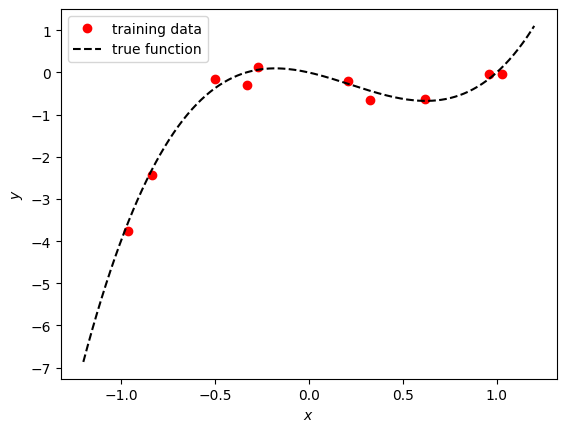

In [4]:
rng = np.random.default_rng(33)   # fixed seed: everybody gets the same data

def f_true(x):
    # the function behind the data (unknown in a real problem)
    return -1.0*x - 2.0*x**2 + 3.0*x**3

sigma = 0.2   # standard deviation of the noise (also unknown in a real problem)

def sample(x):
    # noisy observations y = f_true(x) + noise at the points x (an N x 1 array)
    return f_true(x) + sigma*rng.normal(size=x.shape)

N = 10
x_train = np.linspace(-1, 1, N).reshape(-1, 1) + 0.1*rng.normal(size=(N, 1))
y_train = sample(x_train)

xx = np.linspace(-1.2, 1.2, 200).reshape(-1, 1)   # a fine grid, only used for plotting

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

## 2. A straight line

The function `model` turns features and parameters into a function $x\mapsto\boldsymbol\phi(x)^\top\boldsymbol\theta$.
The features of a straight line are $\boldsymbol\phi(x)=(1,x)$, so $f(x)=\theta_0+\theta_1x$. For $N$ inputs,
`linear_features` returns the $N\times2$ feature matrix $\boldsymbol\Phi$, whose rows are $\boldsymbol\phi(x_n)^\top$.

In [5]:
def model(features, theta):
    # the model x -> phi(x)^T theta, where features(x) returns the N x K feature matrix Phi
    return lambda x: features(x) @ theta

def linear_features(x):
    # features phi(x) = (1, x): returns the N x 2 matrix Phi
    return np.hstack([np.ones_like(x), x])

Try to find a good line by hand: change `theta_guess` and rerun the cell.

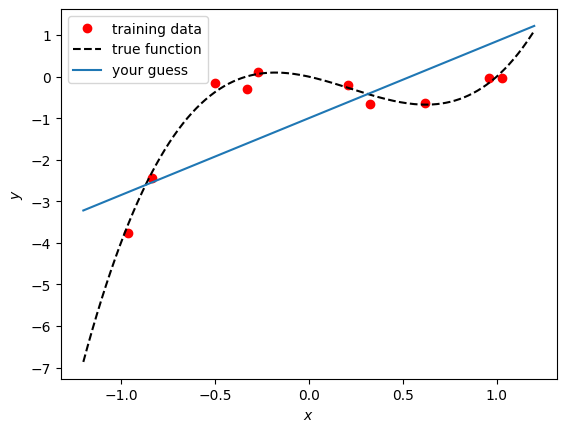

In [6]:
theta_guess = np.array([[-1], [1.85]]) # EDIT: try to find better values
f_guess = model(linear_features, theta_guess)

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.plot(xx, f_guess(xx), label='your guess')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

### Measuring the error
A systematic way to judge a model is the **root-mean-square error**
$$
\mathrm{RMSE}=\sqrt{\frac1N\sum_{n=1}^N\bigl(y_n-f(x_n)\bigr)^2}.
$$
Its square is the empirical risk with the squared loss (Lecture 1). Complete the function.

In [7]:
def rmse(y, y_pred):
    # root-mean-square error between two N x 1 arrays
    return np.sqrt(np.mean((y - y_pred) ** 2)) # EDIT

print('training RMSE of your guess:', rmse(y_train, f_guess(x_train)))

training RMSE of your guess: 1.0398423436575337


### Maximum likelihood
With Gaussian noise, the maximum likelihood estimate $\boldsymbol\theta_{\mathrm{ML}}$ solves the **normal equations**
(Lecture 3)
$$
\boldsymbol\Phi^\top\boldsymbol\Phi\,\boldsymbol\theta=\boldsymbol\Phi^\top\boldsymbol y .
$$
Complete `fit_ml`. Use `np.linalg.solve` rather than computing the inverse $(\boldsymbol\Phi^\top\boldsymbol\Phi)^{-1}$:
solving the system is cheaper and more accurate.

theta_ML = [-0.83807334  1.15566739]


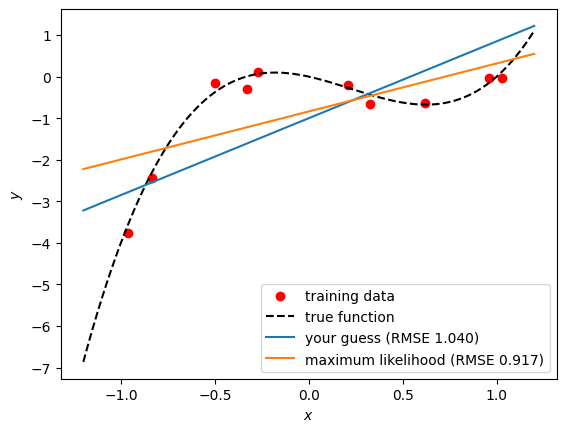

In [8]:
def fit_ml(Phi, y):
    # maximum likelihood estimate: the solution of Phi^T Phi theta = Phi^T y
    return np.linalg.solve(Phi.T @ Phi, Phi.T @ y)   # EDIT

Phi_line = linear_features(x_train)
theta_line = fit_ml(Phi_line, y_train)
f_line = model(linear_features, theta_line)
print('theta_ML =', theta_line.ravel())

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.plot(xx, f_guess(xx), label=f'your guess (RMSE {rmse(y_train, f_guess(x_train)):.3f})')
plt.plot(xx, f_line(xx), label=f'maximum likelihood (RMSE {rmse(y_train, f_line(x_train)):.3f})')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

**Q1.** Does the fitted line describe the data well? Does it describe the true function well?

**Q2.** Why does $\boldsymbol\theta_{\mathrm{ML}}$ give a smaller training RMSE than any other line, including your guess?
(Hint: Lecture 3. What does maximising the likelihood with Gaussian noise amount to?)

Answers

**Q1:** The fitted line does not describe the data well, as it is a compromise between the data points close to the extreme values of the true function. Considering the way the third-degree polynomial true function shapes, the fitted line as it is right now will fail to match possible data further away from the current data along the true function. In other words, the straight line underfits the true function.

**Q2:** This is beacuse maximizing the likelihood under Gaussian noise is mathematically equivalent to minimizing the sum of squared errors (least squares) and the training RMSE is just a strictly increasing function of that sum of squared errors. $\boldsymbol\theta_{\mathrm{ML}}$ is by definition the global minimizer of the training RMSE over all possible straight lines. Therefore, no other lines (including a manual guess) can achieve smaller training MSE.

The next cell computes the residual vector $\boldsymbol r=\boldsymbol y-\boldsymbol\Phi\boldsymbol\theta_{\mathrm{ML}}$ and
$\boldsymbol\Phi^\top\boldsymbol r$.

In [9]:
r = y_train - Phi_line @ theta_line
print('Phi^T r =', (Phi_line.T @ r).ravel())

Phi^T r = [ 3.33066907e-16 -1.54876556e-15]


**Q3.** $\boldsymbol\Phi^\top\boldsymbol r$ is zero up to rounding errors. Which equation says this? What does it mean
geometrically? (Lecture 4)

Answer

**Q3:** The normal equation, $\boldsymbol\Phi^\top\boldsymbol\Phi\boldsymbol\theta_{\mathrm{ML}}=\boldsymbol\Phi^\top r$. After moving everything to one side and factoring out $\boldsymbol\Phi^\top$ gives $\boldsymbol\Phi^\top(y-\boldsymbol\Phi\boldsymbol\theta_{\mathrm{ML}}) = \boldsymbol\Phi^\top r=0$

Geometrically it means that the residual vector r is orthogonal (perpendicular) to every column of $\boldsymbol\Phi$ and therefore orthogonal to the entire column space $Im(\boldsymbol\Phi)$.

## 3. Polynomials of higher degree

A polynomial of degree $M$ has the features $\boldsymbol\phi(x)=(1,x,x^2,\dots,x^M)$, so $K=M+1$. Complete
`poly_features`, then try a few degrees $M$ in the cell after it (MML 9.2.2, Lecture 4).

In [13]:
def poly_features(x, M):
    # features phi(x) = (1, x, ..., x^M): returns the N x (M+1) matrix Phi
    Phi = np.hstack([x**k for k in range(M + 1)])   # EDIT (hint: np.hstack([x**k for k in ...]))
    return Phi

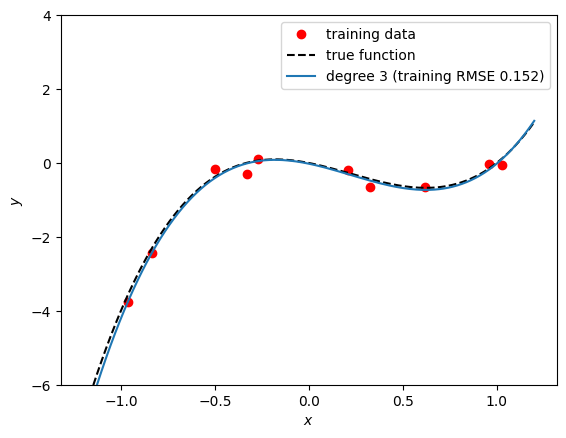

In [22]:
M = 3   # try different degrees
features = lambda x: poly_features(x, M)
theta = fit_ml(features(x_train), y_train)
f_M = model(features, theta)

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.plot(xx, f_M(xx), label=f'degree {M} (training RMSE {rmse(y_train, f_M(x_train)):.3f})')
plt.ylim(-6, 4); plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

Complete the loop, which computes the training RMSE for $M=0,1,\dots,9$.

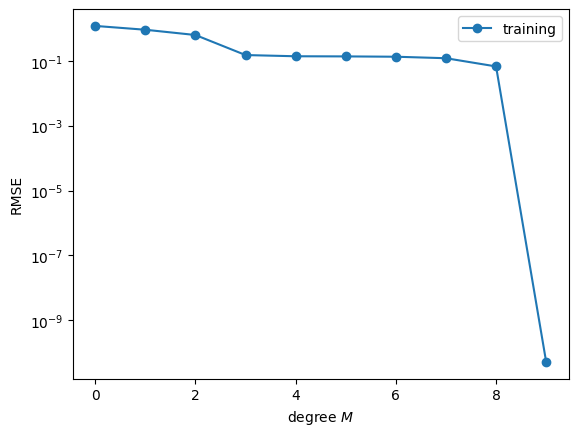

In [26]:
M_max = 9
train_rmse = np.zeros(M_max + 1)
for M in range(M_max + 1):
    features = lambda x: poly_features(x, M)
    theta = fit_ml(features(x_train), y_train) # EDIT
    train_rmse[M] = rmse(y_train, features(x_train)@(theta)) # EDIT

plt.figure()
plt.semilogy(range(M_max + 1), train_rmse, 'o-', label='training')
plt.xlabel('degree $M$'); plt.ylabel('RMSE'); plt.legend();

In [24]:
for M in [1, 3, 6, 9]:
    Phi = poly_features(x_train, M)
    print(f'M = {M}: rank of Phi = {np.linalg.matrix_rank(Phi)}, condition number of Phi^T Phi = {np.linalg.cond(Phi.T @ Phi):.1e}')

M = 1: rank of Phi = 2, condition number of Phi^T Phi = 2.2e+00
M = 3: rank of Phi = 4, condition number of Phi^T Phi = 5.4e+01
M = 6: rank of Phi = 7, condition number of Phi^T Phi = 1.8e+04
M = 9: rank of Phi = 10, condition number of Phi^T Phi = 1.0e+08


**Q4.** Which degree $M$ gives the smallest training RMSE, and why? For which $M$ is the model underfitting, and for which
is it overfitting? (Plot a few of the fits above.)

**Q5.** The condition number of $\boldsymbol\Phi^\top\boldsymbol\Phi$ grows quickly with $M$. Why does that cause
numerical problems? What would happen for $M\ge N=10$? (Hint: the rank of $\boldsymbol\Phi$, Lecture 3.)

Answer

**Q4:** M=9 gives the smallest training RMSE because it makes K equal N: $K=M+1=10=N$, meaning the model passes exactly through every single data point with $RMSE=0$. The underfitting and overfitting of the model depends on the complexity of the true function. Since the degree of the true function is 3, the model is a good fit for $M=3$ and it underfits and overfits for $M<3$ and $M>3$ respectively.

**Q5:** The condition number of a matrix acts as an error amplifier when a computer solves a linear system like $\boldsymbol\Phi^\top\boldsymbol\Phi\boldsymbol\theta=\boldsymbol\Phi^\top y$. This is because computers store a finite amount of numbers and as the condition number increases, when solving the normal equations, those tiny rounding errors (or noise in data) can be multiplied by a factor up to the condition number. That leads to a numerically unstable and inaccurate $\boldsymbol\theta_{\mathrm{ML}}$. As we see in the results above, rounding errors of $M=1$ can be amplified by a factor of only 2.2 while for $M=9$ that same error can be amplified by 100 million. For $M \ge N=10$, the matrix $\boldsymbol\Phi$ has more columns ($K=M+1\ge 11$) than rows ($N=10$), making the rank($\boldsymbol\Phi$) $\le 10 < K$, the columns linearly dependent and $\boldsymbol\Phi^\top\boldsymbol\Phi$ singular (not invertible) and there is no longer a unique solution.

## 4. Training error and test error

Because we generated the data ourselves, we can draw a large **test set** from the same distribution. Its RMSE is close
to the root of the true risk (Lecture 2). In practice you only have your $N$ data points, and a test set may be used only
once, at the very end, to report the performance of the model you have chosen.

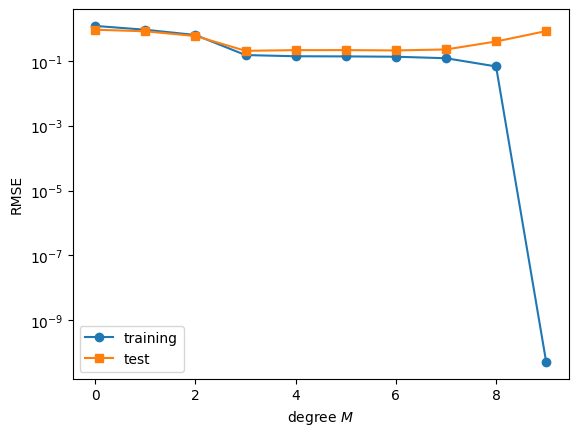

In [29]:
x_test = rng.uniform(-1, 1, size=(1000, 1))
y_test = sample(x_test)

test_rmse = np.zeros(M_max + 1)
for M in range(M_max + 1):
    features = lambda x: poly_features(x, M)
    theta = fit_ml(features(x_train), y_train)
    test_rmse[M] = rmse(y_test, features(x_test)@(theta))   # EDIT

plt.figure()
plt.semilogy(range(M_max + 1), train_rmse, 'o-', label='training')
plt.semilogy(range(M_max + 1), test_rmse, 's-', label='test')
plt.xlabel('degree $M$'); plt.ylabel('RMSE'); plt.legend();

**Q6.** Which degree has the smallest test RMSE? Compare with the true function. Describe overfitting in terms of the two
curves.

Answer

**Q6:** Test RMSE is smallest at $M=3$ which is the degree of the true polynomial function. The test RMSE reaches its lowest point at $M=3$ because that is the exact degree needed to capture the true signal without extra degrees of freedom to chase noise. Overfitting appears as the growing gap between the two curves at higher degrees (especially $M=7,8,9$), where we see training RMSE decreases while the test RMSE gets worse.

## 5. Choosing the degree by cross-validation

The test set must not be used to choose $M$: then it no longer measures the performance on new data (Lecture 2). Instead
we estimate the test error from the training data alone, with **leave-one-out cross-validation**: for each $n$, fit the
model to all training points except $(x_n,y_n)$, and compute the squared error of the prediction at $x_n$. The CV-RMSE is
the root of the average of these $N$ errors.

Complete `loocv_rmse`. The argument `fit` is the fitting method, for example `fit_ml`.

degree chosen by cross-validation: 3


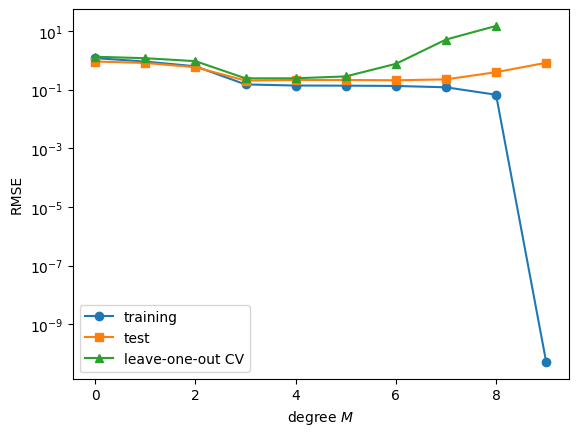

In [30]:
def loocv_rmse(x, y, features, fit):
    # leave-one-out cross-validation estimate of the RMSE
    N = x.shape[0]
    errors = np.zeros(N)
    for n in range(N):
        keep = np.arange(N) != n           # every point except number n
        theta = fit(features(x[keep]), y[keep])            # EDIT: fit to the kept points
        errors[n] = ((y[n] - features(x[n:n+1]) @ theta) ** 2).item()        # EDIT: squared error of the prediction at x_n
    return np.sqrt(np.mean(errors))

M_cv = 8
cv_rmse = np.array([loocv_rmse(x_train, y_train, lambda x: poly_features(x, M), fit_ml) for M in range(M_cv + 1)])
M_best = int(np.argmin(cv_rmse))
print('degree chosen by cross-validation:', M_best)

plt.figure()
plt.semilogy(range(M_max + 1), train_rmse, 'o-', label='training')
plt.semilogy(range(M_max + 1), test_rmse, 's-', label='test')
plt.semilogy(range(M_cv + 1), cv_rmse, '^-', label='leave-one-out CV')
plt.xlabel('degree $M$'); plt.ylabel('RMSE'); plt.legend();

**Q7.** Which degree does cross-validation choose? Does it agree with the test error? Why does the cross-validation curve
stop at $M=8$, i.e. what would go wrong for $M=9$?

Answer

**Q7:** The cross validation chooses degree 3. It does agree with the test error as both methods reached their lowest points at the degree of the true cubic function and then curved upward after $M=3$. The curve stops at $M=8$ since it is only trained on $N-1=9$ data points. At $M=9$, the feature matrix $\boldsymbol\Phi$ has $K=M+1=10$ columns, but only 9 rows. Just like in question 5, having more columns than rows means $rank(\boldsymbol\Phi)\le 9 < K$, the columns become linearly dependent, $\boldsymbol\Phi^\top\boldsymbol\Phi$ is singular and the normal equations no longer have a unique solution.

## 6. Ridge regression

Instead of choosing a small degree, we can keep a flexible model and penalise large parameters. **Ridge regression**
minimises
$$
\|\boldsymbol y-\boldsymbol\Phi\boldsymbol\theta\|^2+\lambda\|\boldsymbol\theta\|^2 ,
$$
and the minimiser is
$$
\boldsymbol\theta_{\mathrm{ridge}}=(\boldsymbol\Phi^\top\boldsymbol\Phi+\lambda\boldsymbol I)^{-1}\boldsymbol\Phi^\top\boldsymbol y .
$$

**Q8.** Derive this formula: compute the gradient of the objective with respect to $\boldsymbol\theta$ and set it to zero.

Answer

**Q8:** Let the ridge regression objective function be
$$J(\boldsymbol{\theta}) = \|\boldsymbol{y} - \boldsymbol{\Phi}\boldsymbol{\theta}\|^2 + \lambda \|\boldsymbol{\theta}\|^2.$$

Expanding the squared norms using $\|\boldsymbol{v}\|^2 = \boldsymbol{v}^\top \boldsymbol{v}$ gives:
$$J(\boldsymbol{\theta}) = (\boldsymbol{y} - \boldsymbol{\Phi}\boldsymbol{\theta})^\top (\boldsymbol{y} - \boldsymbol{\Phi}\boldsymbol{\theta}) + \lambda \boldsymbol{\theta}^\top \boldsymbol{\theta} = \boldsymbol{y}^\top \boldsymbol{y} - 2\boldsymbol{\theta}^\top \boldsymbol{\Phi}^\top \boldsymbol{y} + \boldsymbol{\theta}^\top \boldsymbol{\Phi}^\top \boldsymbol{\Phi}\boldsymbol{\theta} + \lambda \boldsymbol{\theta}^\top \boldsymbol{\theta}.$$

Computing the gradient with respect to $\boldsymbol{\theta}$:
$$\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = -2\boldsymbol{\Phi}^\top \boldsymbol{y} + 2\boldsymbol{\Phi}^\top \boldsymbol{\Phi}\boldsymbol{\theta} + 2\lambda \boldsymbol{\theta}.$$

Setting the gradient equal to zero:
$$-2\boldsymbol{\Phi}^\top \boldsymbol{y} + 2\boldsymbol{\Phi}^\top \boldsymbol{\Phi}\boldsymbol{\theta} + 2\lambda \boldsymbol{\theta} = \boldsymbol{0}.$$

Dividing by $2$, rearranging, and factoring out $\boldsymbol{\theta}$ (using $\lambda \boldsymbol{\theta} = \lambda \boldsymbol{I}\boldsymbol{\theta}$):
$$(\boldsymbol{\Phi}^\top \boldsymbol{\Phi} + \lambda \boldsymbol{I})\boldsymbol{\theta} = \boldsymbol{\Phi}^\top \boldsymbol{y}.$$

Multiplying both sides on the left by $(\boldsymbol{\Phi}^\top \boldsymbol{\Phi} + \lambda \boldsymbol{I})^{-1}$ yields the minimiser:
$$\boldsymbol{\theta}_{\mathrm{ridge}} = (\boldsymbol{\Phi}^\top \boldsymbol{\Phi} + \lambda \boldsymbol{I})^{-1} \boldsymbol{\Phi}^\top \boldsymbol{y}.$$

Complete `fit_ridge` (again with `np.linalg.solve`).

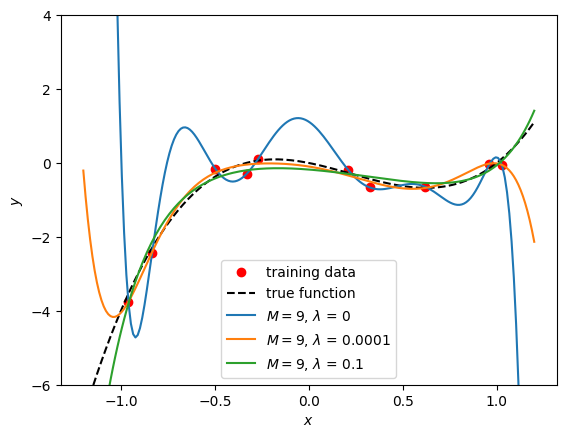

In [31]:
def fit_ridge(Phi, y, lam):
    # ridge regression: minimise ||y - Phi theta||^2 + lam ||theta||^2
    K = Phi.shape[1]
    return np.linalg.solve(Phi.T @ Phi + lam * np.eye(K), Phi.T @ y)   # EDIT

M = 9
features = lambda x: poly_features(x, M)
plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
for lam in [0, 1e-4, 1e-1]:
    theta = fit_ridge(features(x_train), y_train, lam)
    plt.plot(xx, model(features, theta)(xx), label=f'$M={M}$, $\\lambda$ = {lam:g}')
plt.ylim(-6, 4); plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

We now choose $\lambda$ for the degree $M=9$ by leave-one-out cross-validation. (With $\lambda>0$ this works even though
each fit uses only 9 points for 10 parameters.) Complete the computation of the CV-RMSE; the test RMSE is computed only
to compare.

lambda chosen by cross-validation: 3.2e-01


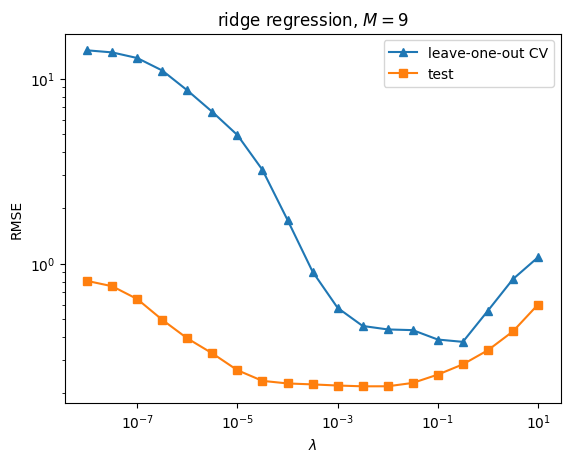

In [32]:
M = 9
features = lambda x: poly_features(x, M)
lams = np.logspace(-8, 1, 19)
cv_ridge = np.array([loocv_rmse(x_train, y_train, features, lambda Phi, y: fit_ridge(Phi, y, lam)) for lam in lams])   # EDIT: array of LOOCV-RMSEs, one per lambda (hint: fit = lambda Phi, y: fit_ridge(Phi, y, lam))
test_ridge = np.array([rmse(y_test, model(features, fit_ridge(features(x_train), y_train, lam))(x_test)) for lam in lams])
lam_best = lams[np.argmin(cv_ridge)]
print(f'lambda chosen by cross-validation: {lam_best:.1e}')

plt.figure()
plt.loglog(lams, cv_ridge, '^-', label='leave-one-out CV')
plt.loglog(lams, test_ridge, 's-', label='test')
plt.xlabel('$\\lambda$'); plt.ylabel('RMSE'); plt.title(f'ridge regression, $M={M}$'); plt.legend();

Finally, the two models chosen by cross-validation are evaluated **once** on the test set.

In [33]:
theta_A = fit_ml(poly_features(x_train, M_best), y_train)
theta_B = fit_ridge(poly_features(x_train, 9), y_train, lam_best)
print(f'A: degree {M_best}, maximum likelihood:   test RMSE = {rmse(y_test, poly_features(x_test, M_best) @ theta_A):.3f}')
print(f'B: degree 9, ridge with lambda = {lam_best:.0e}: test RMSE = {rmse(y_test, poly_features(x_test, 9) @ theta_B):.3f}')
print(f'noise level sigma = {sigma}')

A: degree 3, maximum likelihood:   test RMSE = 0.205
B: degree 9, ridge with lambda = 3e-01: test RMSE = 0.285
noise level sigma = 0.2


**Q9.** Which $\lambda$ does cross-validation choose? Describe what happens for very small and for very large $\lambda$.

**Q10.** Ridge regression is MAP estimation with the prior $\boldsymbol\theta\sim\mathcal N(\boldsymbol 0,b^2\boldsymbol I)$,
with $\lambda=\sigma^2/b^2$ (Lecture 4). With $\sigma=0.2$, which prior standard deviation $b$ corresponds to the chosen
$\lambda$? Why does a prior that prefers small parameters help here?

**Q11.** Why does $\lambda>0$ also cure the numerical problems of Q5? (Hint: the eigenvalues of
$\boldsymbol\Phi^\top\boldsymbol\Phi+\lambda\boldsymbol I$.)

Answer

**Q9:** The cross validation chooses $\lambda = 3.2\text{e-01}$. For very small lambda, the penalty term $\lambda \|\boldsymbol{\theta}\|^2$ vanishes, so ridge regression approaches unregularized maximum likelihood (ordinary least squares). For $M = 9$, this leads to severe overfitting, the curve oscillates wildly to pass through the noisy training points, and both the CV and test RMSE become very large.
For very large lambda, the penalty dominates the objective, forcing all weights $\boldsymbol{\theta}$ to shrink toward 0. The model becomes too flat and rigid to capture the true cubic shape, causing underfitting, which is why both the CV and test RMSE climb back up on the right side of the plot.

**Q10:** Rearranging $\lambda = \sigma^2 / b^2$ gives $b = \sigma / \sqrt{\lambda}$. With $\sigma = 0.2$ and $\lambda = 3.2\text{e-01}$, the prior standard deviation is:
$$b = \frac{0.2}{\sqrt{0.32}} \approx 0.35.$$
A prior that prefers small parameters helps because overfitting high-degree polynomials rely on very large positive and negative weights that cause large oscillations between data points. Pulling the weights toward zero manages those oscillations and produces a smoother curve that generalizes better.

**Q11:** The matrix $\boldsymbol{\Phi}^\top \boldsymbol{\Phi}$ has eigenvalues $\mu_i \ge 0$, and the numerical problems in Q5 happen when the smallest eigenvalue is zero (singular) or very close to zero (huge condition number). Adding $\lambda \boldsymbol{I}$ with $\lambda > 0$ shifts every eigenvalue up to $\mu_i + \lambda \ge \lambda > 0$. Because all eigenvalues are now strictly positive, $\boldsymbol{\Phi}^\top \boldsymbol{\Phi} + \lambda \boldsymbol{I}$ is always invertible (even when $K > N$) and its condition number stays bounded, making the system numerically stable.

## 7. The noise variance

The maximum likelihood estimate of the noise variance is the mean squared residual on the training data (Lecture 3),
$$
\sigma^2_{\mathrm{ML}}=\frac1N\sum_{n=1}^N\bigl(y_n-\boldsymbol\phi(x_n)^\top\boldsymbol\theta_{\mathrm{ML}}\bigr)^2 ,
$$
and dividing by $N-K$ instead of $N$ gives an unbiased estimate. Compute both for the degree chosen by cross-validation.

In [35]:
Phi = poly_features(x_train, M_best)
theta = fit_ml(Phi, y_train)
r = y_train - Phi @ theta
K = M_best + 1
s2_ml = np.sum(r**2) / len(r)        # EDIT
s2_unbiased = np.sum(r**2) / (len(r) - K)   # EDIT
print(f'sigma^2_ML = {s2_ml:.4f},  unbiased estimate = {s2_unbiased:.4f},  true sigma^2 = {sigma**2:.4f}')

sigma^2_ML = 0.0231,  unbiased estimate = 0.0385,  true sigma^2 = 0.0400


With only $N=10$ training points the residuals say little about the shape of the noise distribution. The test set is
large, so we use its residuals to check the Gaussian noise model: the histogram should look like the density of
$\mathcal N(0,\hat\sigma^2)$.

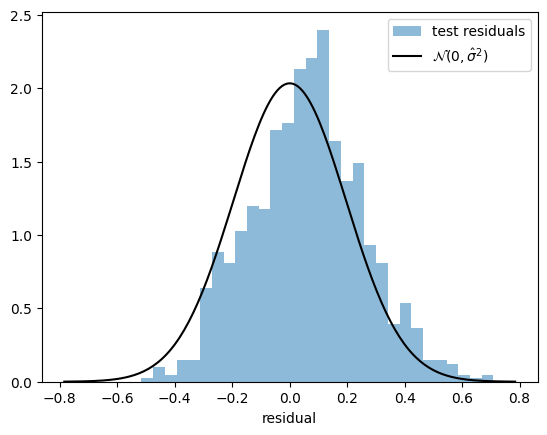

In [36]:
r_test = (y_test - poly_features(x_test, M_best) @ theta).ravel()
s = np.sqrt(s2_unbiased)
t = np.linspace(-4*s, 4*s, 200)
plt.figure()
plt.hist(r_test, bins=30, density=True, alpha=0.5, label='test residuals')
plt.plot(t, np.exp(-t**2/(2*s**2))/np.sqrt(2*np.pi*s**2), 'k', label='$\\mathcal{N}(0,\\hat\\sigma^2)$')
plt.xlabel('residual'); plt.legend();

**Q12.** Which of the two estimates is closer to the true $\sigma^2=0.04$? Why is $\sigma^2_{\mathrm{ML}}$ too small on
average? (Hint: it is a training error, Lecture 2.) Does the histogram support the Gaussian noise model?

Answer

**Q12:** The unbiased estimate (0.0385) is much closer to the true variance $\sigma^2 = 0.0400$ than $\sigma_{\mathrm{ML}}^2 = 0.0231$. $\sigma_{\mathrm{ML}}^2$ is too small on average because it is a training error: $\boldsymbol{\theta}_{\mathrm{ML}}$ is fitted to minimize the squared residuals on the training set, so it partially fits the random noise in the data (using up $K$ degrees of freedom). Dividing by $N$ instead of $N - K$ therefore systematically underestimates the true noise variance.

Yes, the histogram supports the Gaussian noise model. We can see that the test residuals are bell-shaped and closely match the $\mathcal{N}(0, \hat{\sigma}^2)$ curve (with only a slight horizontal shift due to estimating $\boldsymbol{\theta}_{\mathrm{ML}}$ from just $N = 10$ points).

## Optional extras
* Try other features, for example a Fourier basis $\phi_k(x)=\cos(k\pi x)$ and $\sin(k\pi x)$.
* Repeat the experiment with another seed, or with more training points ($N=30$). What changes?
* Find out how `sklearn.linear_model.LinearRegression` and `Ridge` do the same computations.